# ACL Project Milestone 1

# Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834"])
pd.set_option("display.max_columns", 50)

DATA_DIR = "dataset/"
MISSING = r"\N"   # the placeholder this dataset uses for missing values

## 1. Data Cleaning & Auditing

### 1.1 Dataset Loading and Initial EDA

A first look at the data **before any cleaning**. We load every table twice:

- `raw`: exactly as in the files (`\N` stays as text). Used to count the problems.
- `data`: the same files, but with `\N` read as a missing value. Used to explore.

The CSV files themselves are never changed.

In [2]:
table_names = ["circuits", "constructors", "drivers", "seasons", "races", "status", "results",
               "qualifying", "sprint_results", "driver_standings", "constructor_standings",
               "constructor_results", "lap_times", "pit_stops"]

raw = {}
data = {}
for name in table_names:
    raw[name] = pd.read_csv(DATA_DIR + name + ".csv")
    data[name] = pd.read_csv(DATA_DIR + name + ".csv", na_values=MISSING)

pd.DataFrame({
    "rows": {name: len(df) for name, df in raw.items()},
    "columns": {name: df.shape[1] for name, df in raw.items()},
})

,rows,columns
circuits,77,9
constructors,212,5
drivers,861,9
seasons,75,2
races,1125,18
status,139,2
results,26759,18
qualifying,10494,9
sprint_results,360,16
driver_standings,34863,7


#### 1.1.1 First rows of the main tables

In [3]:
for name in ["results", "races", "qualifying"]:
    print(name)
    display(raw[name].head(3))

results


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1


races


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


qualifying


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


- `results` is the main table: one row per driver per race. The target comes from `positionOrder`.
- `races` adds the year and circuit; `qualifying` adds the qualifying position and lap times (`q1`, `q2`, `q3`).
- `\N` is already visible in the first rows, and dates and lap times are stored as text.

#### 1.1.2 Hidden missing values (`\N`) and wrong data types

Missing values pandas finds in raw results: 0
\N values actually in raw results: 122887


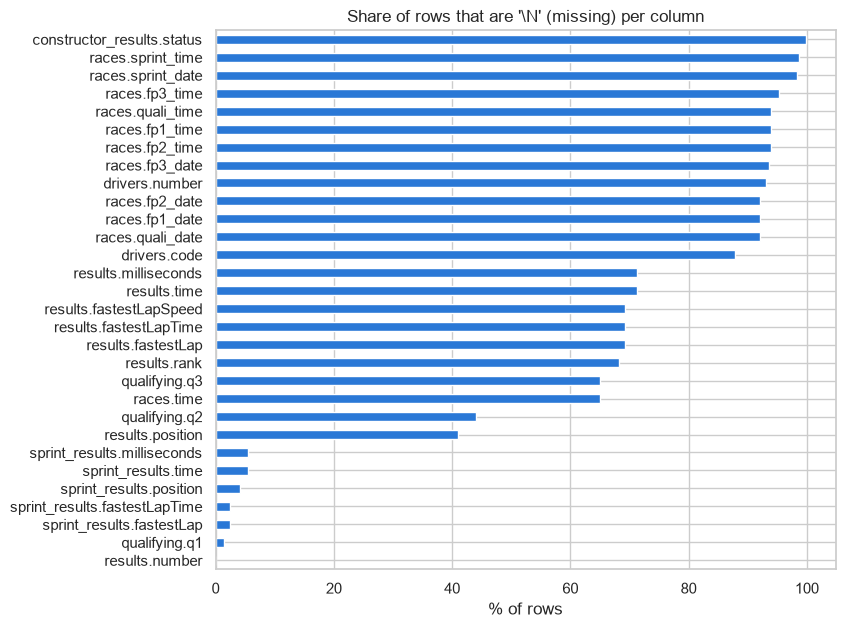

In [4]:
rows = []
for name, df in raw.items():
    for col in df.columns:
        count = (df[col].astype(str) == MISSING).sum()
        if count > 0:
            rows.append({"column": name + "." + col, "count": count, "percent": 100 * count / len(df)})
missing = pd.DataFrame(rows).sort_values("percent")

print("Missing values pandas finds in raw results:", raw["results"].isna().sum().sum())
print(r"\N values actually in raw results:", missing.loc[missing["column"].str.startswith("results."), "count"].sum())

missing.plot.barh(x="column", y="percent", figsize=(8, 7), legend=False)
plt.title(r"Share of rows that are '\N' (missing) per column")
plt.xlabel("% of rows")
plt.ylabel("")
plt.show()

In [5]:
# One '\N' is enough to turn a whole numeric column into text
pd.DataFrame({"raw dtype": raw["results"].dtypes, r"dtype with \N as missing": data["results"].dtypes})

,raw dtype,dtype with \N as missing
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,str,float64
grid,int64,int64
position,str,float64
positionText,str,str
positionOrder,int64,int64
points,float64,float64


- pandas finds **0** missing values in raw `results`, but there are **122,887** `\N` values. The missing data is hidden.
- Because of `\N`, numeric columns like `position`, `milliseconds`, and `rank` are read as text. Reading `\N` as
  missing fixes this.
- Many columns are mostly empty (e.g. `constructor_results.status` 100%, practice-session dates in `races` over 90%).
- Dates (`races.date`, `drivers.dob`) and lap times (`q1`–`q3`, e.g. `"1:26.572"`) are still text.

**Next (1.2):** convert dates to dates and lap times to seconds, and drop the mostly-empty columns.

#### 1.1.3 Data coverage over time

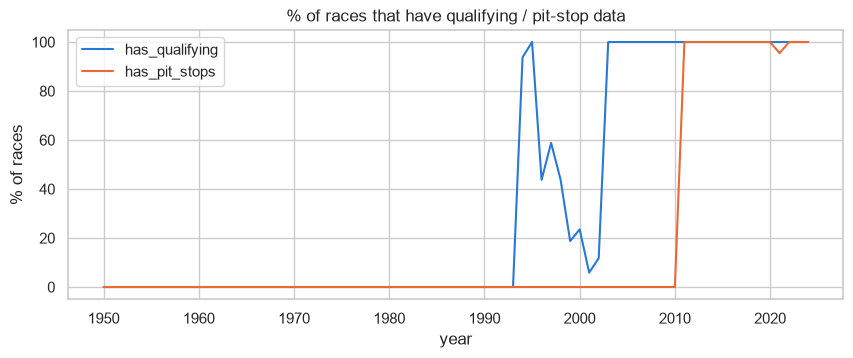

year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
has_qualifying,94.0,100.0,44.0,59.0,44.0,19.0,24.0,6.0,12.0,100.0,100.0


In [6]:
races = data["races"].copy()
races["has_qualifying"] = races["raceId"].isin(data["qualifying"]["raceId"])
races["has_pit_stops"] = races["raceId"].isin(data["pit_stops"]["raceId"])
coverage = races.groupby("year")[["has_qualifying", "has_pit_stops"]].mean() * 100

coverage.plot(figsize=(10, 3.5))
plt.title("% of races that have qualifying / pit-stop data")
plt.ylabel("% of races")
plt.show()

coverage.loc[1994:2004, ["has_qualifying"]].T.round(0)

- Qualifying data starts in **1994**, but between 1996 and 2002 only part of the races have it. It is complete from **2003**.
- Pit-stop data only exists from 2011.
- Since qualifying is one of our most important pre-race inputs, we will most likely model the seasons
  **2003–2024**. This is also a limitation to mention in the report.

#### 1.1.4 Duplicate rows: is (raceId, driverId) unique?

In [7]:
results = data["results"].merge(races[["raceId", "year"]], on="raceId")

duplicates = results[results.duplicated(["raceId", "driverId"], keep=False)]
print("Duplicated rows:", len(duplicates))
print("Driver-race pairs affected:", duplicates.groupby(["raceId", "driverId"]).ngroups)
print("Years:", duplicates["year"].min(), "to", duplicates["year"].max())

duplicates.sort_values(["raceId", "driverId"])[
    ["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "points"]].head(6)

Duplicated rows: 176
Driver-race pairs affected: 85
Years: 1950 to 1978


,raceId,year,driverId,constructorId,grid,positionOrder,points
13188,540,1978,229,54,0,26,0.0
13191,540,1978,229,57,0,29,0.0
17362,717,1964,373,172,1,7,0.0
24298,717,1964,373,172,1,12,0.0
17740,733,1962,465,172,0,22,0.0
17743,733,1962,465,97,0,25,0.0


- 85 driver-race pairs appear more than once (176 rows), all between 1950 and 1978.
- These are **shared drives**: in early F1 drivers could swap cars during a race, so one driver gets two result rows.
- **Next (1.4):** choose a rule for which row to keep, so each driver appears once per race.

#### 1.1.5 The target: podium finishes

Podium rate: 12.7%


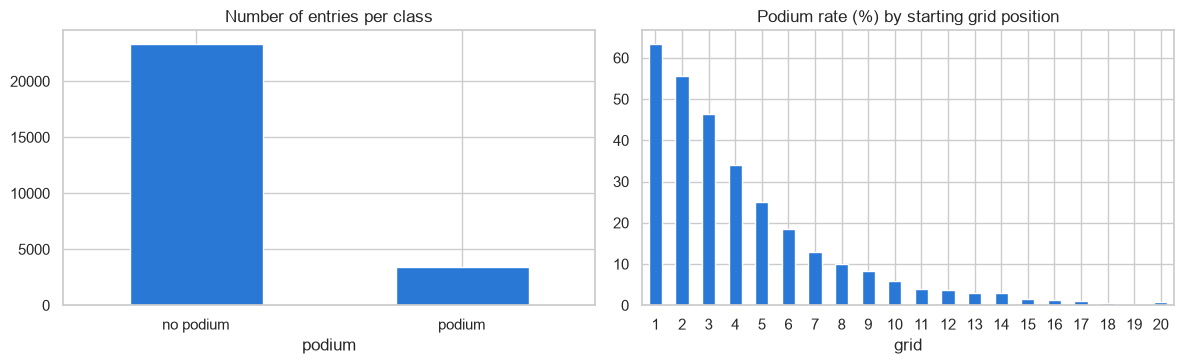

In [8]:
results["podium"] = results["positionOrder"] <= 3
print(f"Podium rate: {results['podium'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
results["podium"].map({True: "podium", False: "no podium"}).value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Number of entries per class")

podium_by_grid = results[results["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100
podium_by_grid.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Podium rate (%) by starting grid position")
plt.tight_layout()
plt.show()

- Only **12.7%** of entries are podiums, so the classes are imbalanced. Accuracy would be misleading, which is
  why we will use PR-AUC and F1.
- The starting position matters a lot: starting from pole gives a 63% podium rate, P3 gives 46%, and past P10 it is
  below 5%. Grid and qualifying position will be our core features.

#### 1.1.6 Race outcomes and special values

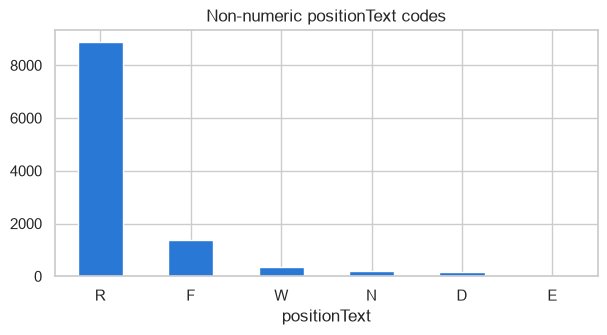

Entries with grid = 0: 1638
Podiums from grid = 0: 0
Grid differs from qualifying position: 23%


In [9]:
codes = results.loc[~results["positionText"].str.isnumeric(), "positionText"].value_counts()
codes.plot.bar(figsize=(7, 3.2), rot=0)
plt.title("Non-numeric positionText codes")
plt.show()

print("Entries with grid = 0:", (results["grid"] == 0).sum())
print("Podiums from grid = 0:", results.loc[results["grid"] == 0, "podium"].sum())

quali = data["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
grid_vs_quali = results.merge(quali, on=["raceId", "driverId"])
grid_vs_quali = grid_vs_quali[grid_vs_quali["grid"] > 0]
print(f"Grid differs from qualifying position: {(grid_vs_quali['grid'] != grid_vs_quali['quali_position']).mean():.0%}")

- `positionText` is not always a number: **R** = retired, **F** = failed to qualify, **W** = withdrawn,
  **N** = not classified, **D** = disqualified, **E** = excluded.
- **F** and **W** drivers never started the race, which is already known before the race, so they will be removed
  from the modelling table.
- `grid = 0` is not a real position (a non-qualifier, or a pit-lane start in modern races) and nobody ever reached
  the podium from it. It is a code, not a missing value, so it is kept and handled when we build features.
- The grid differs from the qualifying position for **23%** of entries (mostly penalties), so both are kept as
  separate features.

#### 1.1.7 Summary

| Finding | What we will do |
|---|---|
| `\N` hides missing values and turns numbers into text | Read `\N` as missing; convert dates and lap times (1.2) |
| Mostly-empty columns (practice dates, `constructor_results.status`) | Drop them (1.2) |
| 85 duplicated driver-race pairs (shared drives, 1950–1978) | Keep one row per driver per race (1.4) |
| Qualifying data complete only from 2003 | Model seasons 2003–2024; note it as a limitation |
| Only 12.7% podiums | Use PR-AUC / F1 and handle class imbalance (4) |
| Grid position strongly predicts podiums; grid ≠ qualifying position | Use both as features (3) |
| F/W entries never started; `grid = 0` is a special value | Remove F/W; keep `grid = 0` as a code (pit-lane start / did not qualify) |
| Extreme pit-stop durations (red flags) | Cap or exclude if used |

### 1.2 Sentinel Handling and Semantic Typing

We clean **copies** of the tables (`clean`). `raw` stays exactly as loaded, and the CSV files are never changed.

Steps: (1) replace the `\N` placeholder with a real missing value, (2) drop columns we will not use,
(3) turn number-like text into numbers, (4) parse dates, (5) convert lap and pit-stop times to seconds,
(6) remove impossible lap times, (7) check the result.

**`grid = 0` is not a missing value.** It is a code meaning the driver did not start from a grid slot: a pit-lane
start, or a driver who did not qualify. It is kept unchanged here and handled when we build features (section 3).

#### 1.2.1 Replace `\N` with a real missing value

In [10]:
clean = {name: df.copy() for name, df in raw.items()}

for df in clean.values():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip().replace(MISSING, np.nan)   # strip also fixes values like "Argentinian "

remaining = sum((df[col].astype(str) == MISSING).sum() for df in clean.values() for col in df.columns)
assert remaining == 0
print(r"\N values left in any table:", remaining)

\N values left in any table: 0


#### 1.2.2 Drop columns we will not use

In [11]:
drop_plan = pd.DataFrame([
    ("all tables", "url", "Wikipedia link, no analytical value"),
    ("races", "fp1/fp2/fp3, quali, sprint date + time", "over 90% missing (only recent seasons); sessions not used"),
    ("races", "time", "65% missing; start time of day is not needed"),
    ("drivers", "number", "93% missing; permanent car number is just a label"),
    ("results, sprint_results", "time", "mixed format (winner's total time vs. '+gap'); same info is in milliseconds"),
    ("constructor_results", "status", "99.9% missing"),
], columns=["table", "column(s)", "reason"])

session_cols = [f"{s}_{p}" for s in ["fp1", "fp2", "fp3", "quali", "sprint"] for p in ["date", "time"]]
to_drop = {
    "races": ["url", "time"] + session_cols,
    "drivers": ["url", "number"],
    "circuits": ["url"], "constructors": ["url"], "seasons": ["url"],
    "results": ["time"], "sprint_results": ["time"],
    "constructor_results": ["status"],
}
for name, cols in to_drop.items():
    clean[name] = clean[name].drop(columns=cols)

drop_plan

,table,column(s),reason
0,all tables,url,"Wikipedia link, no analytical value"
1,races,"fp1/fp2/fp3, quali, sprint date + time",over 90% missing (only recent seasons); sessio...
2,races,time,65% missing; start time of day is not needed
3,drivers,number,93% missing; permanent car number is just a label
4,"results, sprint_results",time,mixed format (winner's total time vs. '+gap');...
5,constructor_results,status,99.9% missing


#### 1.2.3 Turn number-like text into numbers

In [12]:
# A text column becomes numeric only if every non-missing value is a number
converted = []
for name, df in clean.items():
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            as_number = pd.to_numeric(df[col], errors="coerce")
            if as_number.notna().sum() == df[col].notna().sum():
                df[col] = as_number
                converted.append(f"{name}.{col}")

print("Converted to numbers:", converted)

Converted to numbers: ['results.number', 'results.position', 'results.milliseconds', 'results.fastestLap', 'results.rank', 'results.fastestLapSpeed', 'sprint_results.position', 'sprint_results.milliseconds', 'sprint_results.fastestLap']


#### 1.2.4 Parse dates

In [13]:
clean["races"]["date"] = pd.to_datetime(clean["races"]["date"], format="%Y-%m-%d")
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"], format="%Y-%m-%d")

clean["races"]["date"].agg(["min", "max"])

min   1950-05-13
max   2024-12-08
Name: date, dtype: datetime64[us]

#### 1.2.5 Convert lap and pit-stop times to seconds

In [14]:
def to_seconds(value):
    """'1:26.572' -> 86.572, '1:34:50.616' -> 5690.616, '26.898' -> 26.898. Missing stays missing."""
    if pd.isna(value):
        return np.nan
    seconds = 0.0
    for part in str(value).split(":"):
        seconds = seconds * 60 + float(part)
    return seconds


for col in ["q1", "q2", "q3"]:
    clean["qualifying"][col] = clean["qualifying"][col].map(to_seconds)
clean["results"]["fastestLapTime"] = clean["results"]["fastestLapTime"].map(to_seconds)
clean["sprint_results"]["fastestLapTime"] = clean["sprint_results"]["fastestLapTime"].map(to_seconds)
clean["lap_times"]["time"] = clean["lap_times"]["time"].map(to_seconds)
clean["pit_stops"]["duration"] = clean["pit_stops"]["duration"].map(to_seconds)

# Check the parser: these two tables also store the same time in milliseconds
for table, col in [("lap_times", "time"), ("pit_stops", "duration")]:
    df = clean[table]
    match = np.isclose(df[col], df["milliseconds"] / 1000, atol=0.001).mean()
    print(f"{table}.{col}: parsed seconds == milliseconds / 1000 for {match:.2%} of rows")

clean["qualifying"][["q1", "q2", "q3"]].head(3)

lap_times.time: parsed seconds == milliseconds / 1000 for 100.00% of rows
pit_stops.duration: parsed seconds == milliseconds / 1000 for 100.00% of rows


,q1,q2,q3
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079


#### 1.2.6 Remove impossible lap times

**Why:** the post-cleaning EDA (1.5.3) showed one Q1 time of `16:42.640` (1,002.6 s) in the 1995 Japanese Grand
Prix, while the fastest Q1 time of that session was about 1:38 and the median about 1:41. A qualifying lap that is
ten times slower than everyone else's is not physically possible, so it is a **recording error** (most likely a typo
for `1:42.640`).

**Rule:** a qualifying time more than **twice the median of the same session** (same race, same Q1/Q2/Q3) is treated
as a recording error and set to **missing**. We do not replace it with `1:42.640`, because we cannot be sure what the
true time was; a missing value is honest, while a guessed one could be wrong. The rule is written for all three
sessions so that any similar error would also be caught.

In [15]:
quali = clean["qualifying"]
fixed = []
for col in ["q1", "q2", "q3"]:
    session_median = quali.groupby("raceId")[col].transform("median")
    impossible = quali[col] > 2 * session_median
    for i in quali.index[impossible]:
        fixed.append({"raceId": quali.at[i, "raceId"], "driverId": quali.at[i, "driverId"], "session": col,
                      "raw value": raw["qualifying"].at[i, col], "seconds": quali.at[i, col],
                      "session median (s)": round(session_median[i], 1)})
    quali.loc[impossible, col] = np.nan

print("Impossible qualifying times set to missing:", len(fixed))
pd.DataFrame(fixed).merge(clean["races"][["raceId", "year", "name"]], on="raceId")

Impossible qualifying times set to missing: 1


,raceId,driverId,session,raw value,seconds,session median (s),year,name
0,255,87,q1,16:42.640,1002.64,101.5,1995,Japanese Grand Prix


#### 1.2.7 Check the result

In [16]:
def text_columns(df):
    return sum(pd.api.types.is_string_dtype(df[col]) for col in df.columns)


assert all(len(clean[name]) == len(raw[name]) for name in raw)   # 1.2 changes values, never rows

pd.DataFrame({
    "columns before": {name: raw[name].shape[1] for name in raw},
    "columns after": {name: clean[name].shape[1] for name in raw},
    "text columns before": {name: text_columns(raw[name]) for name in raw},
    "text columns after": {name: text_columns(clean[name]) for name in raw},
    "missing before": {name: raw[name].isna().sum().sum() for name in raw},
    "missing after": {name: clean[name].isna().sum().sum() for name in raw},
})

,columns before,columns after,text columns before,text columns after,missing before,missing after
circuits,9,8,5,4,0,0
constructors,5,4,4,3,0,0
drivers,9,7,8,5,0,757
seasons,2,1,1,0,0,0
races,18,6,14,1,0,0
status,2,2,1,1,0,0
results,18,17,9,1,0,103808
qualifying,9,9,3,0,68,11669
sprint_results,16,15,6,1,0,53
driver_standings,7,7,1,1,0,0


In [17]:
# Data types of the main table before and after cleaning
pd.DataFrame({
    "before": raw["results"].dtypes.astype(str),
    "after": clean["results"].dtypes.astype(str).reindex(raw["results"].columns, fill_value="dropped"),
})

,before,after
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,str,float64
grid,int64,int64
position,str,float64
positionText,str,str
positionOrder,int64,int64
points,float64,float64


- No `\N` is left anywhere, and no rows were removed; 1.2 only changes values and types.
- "Missing before" was almost 0 because pandas could not see `\N`. "Missing after" shows the real number of missing
  values, which 1.5 will explore.
- Number columns hidden as text (`position`, `milliseconds`, `rank`, ...) are now numeric, dates are real dates,
  and qualifying, lap, and pit-stop times are numbers in seconds. The parser agrees with the `milliseconds` columns.
- What is still text is real text: names, nationalities, `status`, `positionText` (codes such as R, F, W), and the
  pit-stop clock time.
- `grid = 0` is kept as a code (pit-lane start or did not qualify).

### 1.3 Primary-Key and Foreign-Key Validation

Before joining tables we check that the links between them can be trusted:

- **Primary key:** the column(s) that identify one row. It must be unique and never missing.
- **Foreign key:** a column that points to a row in another table (e.g. `results.raceId → races`). Every value must
  exist in that table; a value that does not is an **orphan**.

All checks run on the cleaned tables (`clean`). If a primary or foreign key ever breaks, the `assert` stops the notebook.

#### 1.3.1 Primary keys: unique and never missing

In [18]:
primary_keys = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "seasons": ["year"], "races": ["raceId"], "status": ["statusId"], "results": ["resultId"],
    "qualifying": ["qualifyId"], "sprint_results": ["resultId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"],      # no id column: one row per driver per lap
    "pit_stops": ["raceId", "driverId", "stop"],     # no id column: one row per driver per stop
}


def check_primary_key(df, columns):
    """Count duplicated keys and rows where part of the key is missing."""
    return {
        "key": ", ".join(columns),
        "rows": len(df),
        "duplicates": df.duplicated(columns).sum(),
        "missing": df[columns].isna().any(axis=1).sum(),
    }


pk_report = pd.DataFrame([{"table": name, **check_primary_key(clean[name], cols)}
                          for name, cols in primary_keys.items()])
pk_report["OK"] = (pk_report["duplicates"] == 0) & (pk_report["missing"] == 0)
assert pk_report["OK"].all()
pk_report

,table,key,rows,duplicates,missing,OK
0,circuits,circuitId,77,0,0,True
1,constructors,constructorId,212,0,0,True
2,drivers,driverId,861,0,0,True
3,seasons,year,75,0,0,True
4,races,raceId,1125,0,0,True
5,status,statusId,139,0,0,True
6,results,resultId,26759,0,0,True
7,qualifying,qualifyId,10494,0,0,True
8,sprint_results,resultId,360,0,0,True
9,driver_standings,driverStandingsId,34863,0,0,True


#### 1.3.2 Foreign keys: every reference exists

In [19]:
# (child table, column, parent table) - the column has the same name in the parent table
foreign_keys = [
    ("races", "circuitId", "circuits"), ("races", "year", "seasons"),
    ("results", "raceId", "races"), ("results", "driverId", "drivers"),
    ("results", "constructorId", "constructors"), ("results", "statusId", "status"),
    ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
    ("qualifying", "constructorId", "constructors"),
    ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
    ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
    ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
    ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
    ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
    ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
    ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
]


def check_foreign_key(child, column, parent):
    """Count missing references and references that do not exist in the parent table (orphans)."""
    values = clean[child][column]
    return {
        "relationship": f"{child}.{column} → {parent}",
        "missing": values.isna().sum(),
        "orphans": (~values.dropna().isin(clean[parent][column])).sum(),
    }


fk_report = pd.DataFrame([check_foreign_key(*fk) for fk in foreign_keys])
fk_report["OK"] = (fk_report["missing"] == 0) & (fk_report["orphans"] == 0)
assert fk_report["OK"].all()
fk_report

,relationship,missing,orphans,OK
0,races.circuitId → circuits,0,0,True
1,races.year → seasons,0,0,True
2,results.raceId → races,0,0,True
3,results.driverId → drivers,0,0,True
4,results.constructorId → constructors,0,0,True
5,results.statusId → status,0,0,True
6,qualifying.raceId → races,0,0,True
7,qualifying.driverId → drivers,0,0,True
8,qualifying.constructorId → constructors,0,0,True
9,sprint_results.raceId → races,0,0,True


#### 1.3.3 Consistency checks within each race

In [20]:
# Inside one race, some values should never repeat. Count the rows that break each rule.
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")

checks = {
    "same driver twice in a race": res.duplicated(["raceId", "driverId"], keep=False),
    "two drivers with the same finishing position": res.duplicated(["raceId", "positionOrder"], keep=False),
    "two drivers on the same grid slot (grid > 0)": (res["grid"] > 0) & res.duplicated(["raceId", "grid"], keep=False),
    "official position differs from positionOrder": res["position"].notna() & (res["position"] != res["positionOrder"]),
}
pd.DataFrame([{
    "check (results)": name,
    "rows": mask.sum(),
    "races": res.loc[mask, "raceId"].nunique(),
    "seasons": f"{res.loc[mask, 'year'].min()}–{res.loc[mask, 'year'].max()}" if mask.any() else "-",
    "races since 2003": res.loc[mask & (res["year"] >= 2003), "raceId"].nunique(),
} for name, mask in checks.items()])

,check (results),rows,races,seasons,races since 2003
0,same driver twice in a race,176,42,1950–1978,0
1,two drivers with the same finishing position,228,46,1950–1964,0
2,two drivers on the same grid slot (grid > 0),377,106,1950–2024,4
3,official position differs from positionOrder,13,1,1983–1983,0


In [21]:
# The same kind of rules in the other tables (0 = consistent)
pd.Series({
    "races: two races with the same (year, round)": clean["races"].duplicated(["year", "round"]).sum(),
    "qualifying: one driver twice in a race": clean["qualifying"].duplicated(["raceId", "driverId"]).sum(),
    "qualifying: two drivers with the same position": clean["qualifying"].duplicated(["raceId", "position"]).sum(),
    "sprint_results: one driver twice in a sprint": clean["sprint_results"].duplicated(["raceId", "driverId"]).sum(),
    "driver_standings: one driver twice after a race": clean["driver_standings"].duplicated(["raceId", "driverId"]).sum(),
    "driver_standings: two drivers with the same position": clean["driver_standings"].duplicated(["raceId", "position"]).sum(),
    "constructor_standings: one team twice after a race": clean["constructor_standings"].duplicated(["raceId", "constructorId"]).sum(),
    "constructor_results: one team twice in a race": clean["constructor_results"].duplicated(["raceId", "constructorId"]).sum(),
    "results: negative grid, laps, or points": (clean["results"][["grid", "laps", "points"]] < 0).any(axis=1).sum(),
}, name="rows breaking the rule").to_frame()

,rows breaking the rule
"races: two races with the same (year, round)",0
qualifying: one driver twice in a race,0
qualifying: two drivers with the same position,0
sprint_results: one driver twice in a sprint,0
driver_standings: one driver twice after a race,0
driver_standings: two drivers with the same position,0
constructor_standings: one team twice after a race,0
constructor_results: one team twice in a race,0
"results: negative grid, laps, or points",0


In [22]:
# The one race where position and positionOrder disagree: the official result has no 2nd place
odd_race = res.loc[checks["official position differs from positionOrder"], "raceId"].iloc[0]
(res[res["raceId"] == odd_race].sort_values("positionOrder")
 [["raceId", "year", "driverId", "position", "positionText", "positionOrder", "points"]].head(4))

,raceId,year,driverId,position,positionText,positionOrder,points
10655,452,1983,137,1.0,1,1,9.0
10656,452,1983,182,3.0,3,2,4.0
10657,452,1983,172,4.0,4,3,3.0
10658,452,1983,175,5.0,5,4,2.0


| # | Inconsistency | Cause | What we do |
|---|---|---|---|
| 1 | Same driver twice in a race (85 driver-race pairs in 42 races, 1950–1978) | **Shared drives**: a driver drove two cars in one race | Fixed in **1.4** with a documented keep rule |
| 2 | Two drivers with the same finishing position (46 races, 1950–1964) | **Shared car**: both drivers are credited with that car's result | **Kept.** It is correct history; it also explains why some old races have more than three podium rows |
| 3 | Two drivers on the same grid slot (106 races, mostly before 2000; 4 since 2003) | Recording errors in the grid column | **Kept and noted.** The data has no way to tell which value is right. For 2003+ only 4 races are affected, and the qualifying position is available as a second source |
| 4 | `position` ≠ `positionOrder` (13 rows, one race in 1983) | The official result leaves 2nd place empty (that finisher was disqualified and nobody moved up); `positionOrder` renumbers 1, 2, 3, ... | **Kept.** The target uses `positionOrder`, as the task defines it |

All other tables pass every rule (0 rows in the table above).

#### 1.3.4 Cross-table consistency

In [23]:
# Does every driver-race pair in the detail tables also appear in results?
results_pairs = clean["results"][["raceId", "driverId"]].drop_duplicates()


def pairs_not_in_results(table):
    pairs = clean[table][["raceId", "driverId"]].drop_duplicates()
    merged = pairs.merge(results_pairs, how="left", indicator=True)
    return merged[merged["_merge"] == "left_only"].drop(columns="_merge")


pd.Series({table: len(pairs_not_in_results(table))
           for table in ["qualifying", "sprint_results", "lap_times", "pit_stops", "driver_standings"]},
          name="driver-race pairs not in results").to_frame()

,driver-race pairs not in results
qualifying,0
sprint_results,0
lap_times,0
pit_stops,0
driver_standings,8664


In [24]:
# Why driver_standings has extra pairs: did those drivers race in other rounds of the same season?
race_year = clean["races"][["raceId", "year", "round"]]
not_raced = pairs_not_in_results("driver_standings").merge(race_year, on="raceId")
season_drivers = results_pairs.merge(race_year, on="raceId")[["year", "driverId"]].drop_duplicates()
share = not_raced.merge(season_drivers, on=["year", "driverId"]).shape[0] / len(not_raced)
print(f"Standings rows for a race the driver did not enter: {len(not_raced):,}")
print(f"...of which the driver raced in another round of that season: {share:.1%}")

# Where do these rows fall compared with the driver's own races that season?
rounds = (results_pairs.merge(race_year, on="raceId")
          .groupby(["driverId", "year"])["round"].agg(first_race="min", last_race="max").reset_index())
timing = not_raced.merge(rounds, on=["driverId", "year"])
pd.Series({
    "before the driver's first race of the season": (timing["round"] < timing["first_race"]).sum(),
    "between two of the driver's races": ((timing["round"] > timing["first_race"]) & (timing["round"] < timing["last_race"])).sum(),
    "after the driver's last race of the season": (timing["round"] > timing["last_race"]).sum(),
}, name="standings rows").to_frame()

Standings rows for a race the driver did not enter: 8,664
...of which the driver raced in another round of that season: 100.0%


,standings rows
before the driver's first race of the season,0
between two of the driver's races,1705
after the driver's last race of the season,6959


In [25]:
# Is a driver listed with the same team in qualifying and in the race?
team_names = clean["constructors"].set_index("constructorId")["name"]
teams = clean["qualifying"].merge(clean["results"][["raceId", "driverId", "constructorId"]],
                                  on=["raceId", "driverId"], suffixes=("_quali", "_race"))
mismatch = teams[teams["constructorId_quali"] != teams["constructorId_race"]].merge(race_year[["raceId", "year"]], on="raceId")
print("Drivers with a different team in qualifying and in the race:", len(mismatch))
mismatch.assign(team_quali=mismatch["constructorId_quali"].map(team_names),
                team_race=mismatch["constructorId_race"].map(team_names))[
    ["raceId", "year", "driverId", "team_quali", "team_race"]]

Drivers with a different team in qualifying and in the race: 10


,raceId,year,driverId,team_quali,team_race
0,937,2015,829,Marussia,Manor Marussia
1,937,2015,833,Marussia,Manor Marussia
2,941,2015,829,Marussia,Manor Marussia
3,941,2015,833,Marussia,Manor Marussia
4,942,2015,834,Marussia,Manor Marussia
5,942,2015,829,Marussia,Manor Marussia
6,943,2015,834,Marussia,Manor Marussia
7,943,2015,829,Marussia,Manor Marussia
8,944,2015,834,Marussia,Manor Marussia
9,944,2015,829,Marussia,Manor Marussia


In [26]:
# Fix: give these qualifying rows the team the driver raced for (one id per team)
q = clean["qualifying"]
for _, row in mismatch.iterrows():
    same_entry = (q["raceId"] == row["raceId"]) & (q["driverId"] == row["driverId"])
    q.loc[same_entry, "constructorId"] = row["constructorId_race"]

recheck = q.merge(clean["results"][["raceId", "driverId", "constructorId"]],
                  on=["raceId", "driverId"], suffixes=("_quali", "_race"))
left = (recheck["constructorId_quali"] != recheck["constructorId_race"]).sum()
assert left == 0
print("Drivers with a different team in qualifying and in the race after the fix:", left)

Drivers with a different team in qualifying and in the race after the fix: 0


- `qualifying`, `sprint_results`, `lap_times`, and `pit_stops` only contain drivers who are in `results` for that race.
- `driver_standings` has **8,664** extra driver-race pairs. This is **not an error**. `driver_standings` is the
  championship table after each race. Once a driver has raced in a season, the table keeps listing them in every
  later round, with their points frozen, even in rounds they did not enter. The table above confirms this: no such
  row comes before a driver's first race; they all come between two of the driver's races or after their last one,
  and in 100% of cases the driver raced in another round of that season.
  **Consequence for section 3:** the standings row of a race already includes that race's result. A driver's
  standing *before* a race must therefore be taken from the **previous** round of `driver_standings`, never from the
  same race.
- The 10 team mismatches were all one team in 2015: **Marussia** in qualifying vs. **Manor Marussia** in the race
  (two `constructorId`s for one rebranded team), not a driver changing teams. **Fixed:** these qualifying rows now
  use the team from `results`, and 0 mismatches remain. We keep the two ids themselves (206 for 2012–2014, 209 for
  2015–2016), the same way the dataset stores every other team rename (e.g. Toro Rosso → AlphaTauri).

#### 1.3.5 Conclusion

| Check | Result |
|---|---|
| Primary keys (14 tables) | All unique and never missing |
| Foreign keys (23 relationships) | No missing references, no orphans |
| Consistency within a race | 4 issues, all in `results`: shared drives (fixed in **1.4**), shared cars and the 1983 vacant place (correct history, kept), 106 races with repeated grid slots (recording errors, noted) |
| Cross-table consistency | Detail tables match `results`; standings keep listing drivers in rounds they skipped (handled in section 3); Marussia team id **fixed** |

The tables can be joined safely. The remaining structural problem is the duplicated driver-race rows in `results`,
which are fixed in **1.4**.

### 1.4 Driver-Race Grain and Shared-Drive Duplicate Handling

**Why the grain matters.** Our model answers one question per row: *"will this driver finish on the podium in
this race?"*. So the modelling table must have **exactly one row per (`raceId`, `driverId`)**. If a driver appeared
twice in the same race, that race-driver would be counted twice in training and evaluation, and the two rows could
even carry contradictory labels (one podium, one not).

Section 1.3.3 showed that `results` breaks this rule. This section explains why, compares three ways to fix it, applies
the chosen rule, and verifies the result.

#### 1.4.1 The problem: shared drives

In [27]:
results_before = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")
results_before["podium"] = results_before["positionOrder"] <= 3

dups = results_before[results_before.duplicated(["raceId", "driverId"], keep=False)]
pairs = dups.groupby(["raceId", "driverId"])

print(f"Driver-race pairs that appear more than once: {pairs.ngroups}")
print(f"Rows involved: {len(dups)}  ->  extra rows to remove: {len(dups) - pairs.ngroups}")
print(f"Seasons: {dups['year'].min()}–{dups['year'].max()}")
print("Rows per pair:", pairs.size().value_counts().to_dict())
print("Pairs where every row has a real grid slot (grid > 0):", pairs["grid"].apply(lambda g: (g > 0).all()).sum())
print("Pairs with a podium in at least one row:", pairs["podium"].any().sum())

Driver-race pairs that appear more than once: 85
Rows involved: 176  ->  extra rows to remove: 91
Seasons: 1950–1978
Rows per pair: {2: 79, 3: 6}
Pairs where every row has a real grid slot (grid > 0): 82
Pairs with a podium in at least one row: 22


In [28]:
# One shared drive in detail: the first pair that includes a podium
example_race, example_driver = pairs["podium"].any().loc[lambda s: s].index[0]
(dups[(dups["raceId"] == example_race) & (dups["driverId"] == example_driver)]
 .merge(clean["status"], on="statusId")
 [["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "status"]])

,raceId,year,driverId,constructorId,grid,positionOrder,points,laps,status
0,746,1960,475,170,1,17,0.0,40,Suspension
1,746,1960,475,170,8,3,0.0,80,Finished


**What a shared drive is.** In early Formula 1 (mainly the 1950s), a team could move a driver into a different car
during the race, for example when the driver's own car broke down. The dataset stores **one row per car**, not one
row per driver, so a driver who drove two cars in a race gets two rows (and three rows if they drove three cars).

**The size of the problem.**
- **85 driver-race pairs** appear more than once: 79 with 2 rows and 6 with 3 rows. That is 176 rows, of which
  **91 are extra** and must go.
- All of them are from **1950–1978**. There are none in the 2003–2024 seasons we plan to model, but the
  data-engineering questions in section 2 use all seasons, so the fix matters there.
- **22 pairs include a podium** in at least one row, so the choice of rule changes the target for those drivers.

**Reading the example above.** Both rows describe the same driver in the same race (1960, same team):
- Row 1 is the driver's own car. It started from **grid 1**, retired with a suspension failure after **40 laps**, and
  is classified 17th.
- Row 2 is a second car of the same team. It started from **grid 8**, ran all **80 laps**, and **finished 3rd**.
  The driver took this car over during the race.

Important: `grid` and `laps` describe the **car**, not the driver. In 82 of the 85 pairs every row has a real grid
slot, so the data cannot tell us which car the driver started in. A rule like "keep the car the driver started
in" is therefore not reliable, and we choose between the three rules below instead.

#### 1.4.2 Choosing a rule: three candidates compared

We compare three rules for turning each duplicated pair into one row:

- **A: keep the row with the best finishing position** (lowest `positionOrder`). The driver is credited with the best
  result they achieved in that race.
- **B: keep the first row** (lowest `resultId`), i.e. the row that happens to come first in the file.
- **C: drop every duplicated pair**, i.e. remove all rows of the 85 driver-race pairs.

The comparison counts, for the 85 pairs, how many podiums each rule keeps and how many it **loses**: a podium is lost
when the driver did reach the podium in one of their cars, but the rule keeps a non-podium row (or no row at all).

In [29]:
def keep_best(df):
    """Rule A: per driver-race pair, keep the row with the lowest positionOrder."""
    return df.sort_values(["raceId", "driverId", "positionOrder"]).drop_duplicates(["raceId", "driverId"])


def keep_first(df):
    """Rule B: per driver-race pair, keep the row with the lowest resultId."""
    return df.sort_values("resultId").drop_duplicates(["raceId", "driverId"])


def drop_all(df):
    """Rule C: remove every row of a duplicated driver-race pair."""
    return df[~df.duplicated(["raceId", "driverId"], keep=False)]


any_podium = pairs["podium"].any()   # did the driver reach the podium in at least one of their cars?
comparison = []
for name, rule in {"A: keep best finishing position": keep_best,
                   "B: keep first row": keep_first,
                   "C: drop every duplicated pair": drop_all}.items():
    kept = rule(results_before).set_index(["raceId", "driverId"])
    label = kept["podium"].reindex(any_podium.index)          # missing if the rule dropped the pair
    comparison.append({
        "rule": name,
        "rows kept": len(kept),
        "shared-drive pairs kept": label.notna().sum(),
        "podiums kept (of these pairs)": (label == True).sum(),
        "podiums lost": (any_podium & (label != True)).sum(),
    })
pd.DataFrame(comparison)

,rule,rows kept,shared-drive pairs kept,podiums kept (of these pairs),podiums lost
0,A: keep best finishing position,26668,85,22,0
1,B: keep first row,26668,85,6,16
2,C: drop every duplicated pair,26583,0,0,22


In [30]:
# Does rule A also keep the car the driver drove the most?
best_rows = keep_best(dups).set_index(["raceId", "driverId"])
most_laps = pairs["laps"].max()
share = (best_rows["laps"] == most_laps.reindex(best_rows.index)).mean()
print(f"The row with the best finishing position is also the row with the most laps in {share:.0%} of pairs")

The row with the best finishing position is also the row with the most laps in 100% of pairs


**Decision: rule A, keep the row with the best finishing position (lowest `positionOrder`).**

Why rule A fits our task:
1. **It answers our question correctly.** The target asks *"did this driver finish on the podium in this race?"*.
   If any of the driver's cars reached the podium, the honest answer is yes. Rule A keeps all 22 of these
   podiums; it loses **0**.
2. **It matches how the data credits shared drives.** In this dataset, a shared car's result is credited to every
   driver who drove it (1.3.3, check 2: two drivers with the same finishing position). Crediting the driver with
   their best car follows the same convention.
3. **It is the car the driver drove the most.** The best-position row is also the row with the most laps in 100%
   of the pairs, so we keep the car that represents most of the driver's race.
4. **It is simple and reproducible.** One sort plus `drop_duplicates`, with no manual choices.

Why not the others:
- **Rule B (keep the first row) loses 16 podiums.** Nothing in the data says the first row is the driver's
  "main" car; the order of rows is just how the file was stored. B would label 16 drivers as "no podium" although
  they finished on the podium.
- **Rule C (drop all pairs) loses all 22 podiums** and removes 176 rows. It is the simplest rule, and it would not
  affect the 2003–2024 modelling table, but it throws away real race results that section 2 (all seasons) uses.

**Limitation (stated for the report).** For these 85 pairs, the kept row's `grid` and `constructorId` belong to
the best-result car, which is not always the car the driver started in (in the example, grid 8 instead of 1).
This affects 85 of 26,759 rows (0.3%), all before 1979, so it cannot influence the model trained on 2003–2024.

#### 1.4.3 Applying rule A

In [31]:
rows_before = len(clean["results"])
clean["results"] = (clean["results"]
                    .sort_values(["raceId", "driverId", "positionOrder"])
                    .drop_duplicates(["raceId", "driverId"], keep="first")   # keep the best finishing position
                    .sort_values("resultId")
                    .reset_index(drop=True))
print(f"results: {rows_before:,} rows -> {len(clean['results']):,} rows ({rows_before - len(clean['results'])} removed)")

results: 26,759 rows -> 26,668 rows (91 removed)


#### 1.4.4 Verifying the new grain

In [32]:
assert not clean["results"].duplicated(["raceId", "driverId"]).any()   # exactly one row per driver per race

podium_after = clean["results"]["positionOrder"] <= 3
drivers_on_podium_before = results_before.groupby(["raceId", "driverId"])["podium"].any().sum()
assert podium_after.sum() == drivers_on_podium_before   # rule A loses no driver's podium

pd.Series({
    "rows before": len(results_before),
    "rows after": len(clean["results"]),
    "duplicated (raceId, driverId) pairs after": clean["results"].duplicated(["raceId", "driverId"]).sum(),
    "podium rows before (a driver can count twice)": results_before["podium"].sum(),
    "drivers who reached the podium in a race": drivers_on_podium_before,
    "podium rows after (one per driver)": podium_after.sum(),
    "races with more than 3 podium drivers (shared cars)": (podium_after.groupby(clean["results"]["raceId"]).sum() > 3).sum(),
}, name="value").to_frame()

,value
rows before,26759
rows after,26668
"duplicated (raceId, driverId) pairs after",0
podium rows before (a driver can count twice),3397
drivers who reached the podium in a race,3395
podium rows after (one per driver),3395
races with more than 3 podium drivers (shared cars),18


**Result.**
- `results` now has **exactly one row per (`raceId`, `driverId`)**: 26,759 → 26,668 rows (91 removed). The `assert`
  stops the notebook if this ever breaks.
- **No podium was lost.** Before the fix there were 3,397 podium rows, but two drivers were counted twice (a podium
  in two of their cars). Counting each driver once gives **3,395** drivers who reached the podium, and the cleaned
  table has exactly **3,395** podium rows (also checked with an `assert`).
- **18 old races still have more than 3 podium drivers.** These are not duplicates: they are *different* drivers who
  shared one car, and each is credited with that car's result (1.3.3, check 2). They stay, because each row is still
  a different driver in that race.

From here on, `clean["results"]` is the table at the correct grain for the modelling table (section 3.2).

### 1.5 Post-Cleaning EDA and Cleaning Impact

1.1 explored the data **before** cleaning. Here we explore it **after** cleaning (`clean`) and compare the two
(`raw` vs. `clean`), to show what each cleaning step changed and that the cleaning did not distort the data.

#### 1.5.1 Cleaning log: what changed in each table

In [33]:
cleaning_log = pd.DataFrame({
    "rows before": {name: len(raw[name]) for name in raw},
    "rows after": {name: len(clean[name]) for name in raw},
    "columns before": {name: raw[name].shape[1] for name in raw},
    "columns after": {name: clean[name].shape[1] for name in raw},
    r"\N values replaced": {name: (raw[name].astype(str) == MISSING).sum().sum() for name in raw},
    "columns retyped": {name: sum(raw[name][col].dtype != clean[name][col].dtype for col in clean[name].columns)
                        for name in raw},
})
cleaning_log

,rows before,rows after,columns before,columns after,\N values replaced,columns retyped
circuits,77,77,9,8,0,0
constructors,212,212,5,4,0,0
drivers,861,861,9,7,1559,1
seasons,75,75,2,1,0,0
races,1125,1125,18,6,11349,1
status,139,139,2,2,0,0
results,26759,26668,18,17,122887,7
qualifying,10494,10494,9,9,11600,3
sprint_results,360,360,16,15,73,4
driver_standings,34863,34863,7,7,0,0


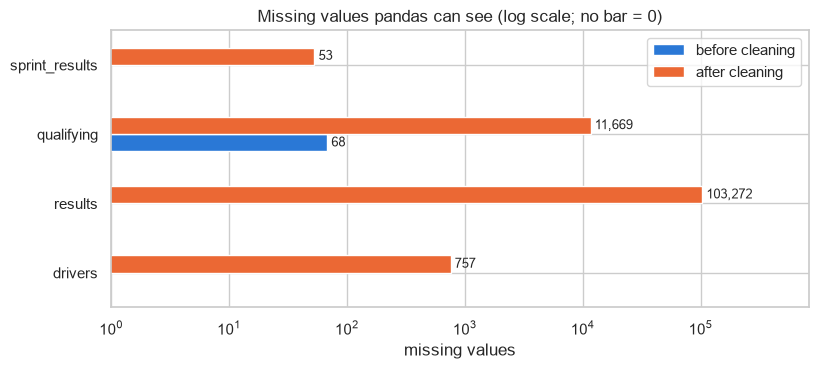

In [34]:
# Missing values pandas can see, before vs. after cleaning (tables that have any)
missing_compare = pd.DataFrame({
    "before cleaning": {name: raw[name].isna().sum().sum() for name in raw},
    "after cleaning": {name: clean[name].isna().sum().sum() for name in raw},
})
missing_compare = missing_compare[missing_compare.sum(axis=1) > 0]

ax = missing_compare.plot.barh(figsize=(9, 3.6), logx=True)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=9)
ax.set_xlim(1, missing_compare.values.max() * 8)
ax.set_title("Missing values pandas can see (log scale; no bar = 0)")
ax.set_xlabel("missing values")
plt.show()

- **Rows:** only `results` changed (26,759 → 26,668), because of the shared-drive fix in 1.4. Every other table
  keeps all its rows.
- **Columns:** 20 unused columns were dropped (1.2.2), mostly in `races` (18 → 6 columns: the session dates and times).
- **`\N` values:** 160,076 placeholders were replaced, 122,887 of them in `results`.
- **Types:** 18 columns now have their real type: numbers, dates (`races.date`, `drivers.dob`), or seconds
  (`q1`–`q3`, fastest lap, lap and pit-stop times).
- **The plot shows the main effect of cleaning:** before, pandas could see almost no missing values (only 68 empty
  fields in `qualifying`). After cleaning, the real missing values are visible, e.g. 103,272 in `results`.

#### 1.5.2 Real missing values after cleaning

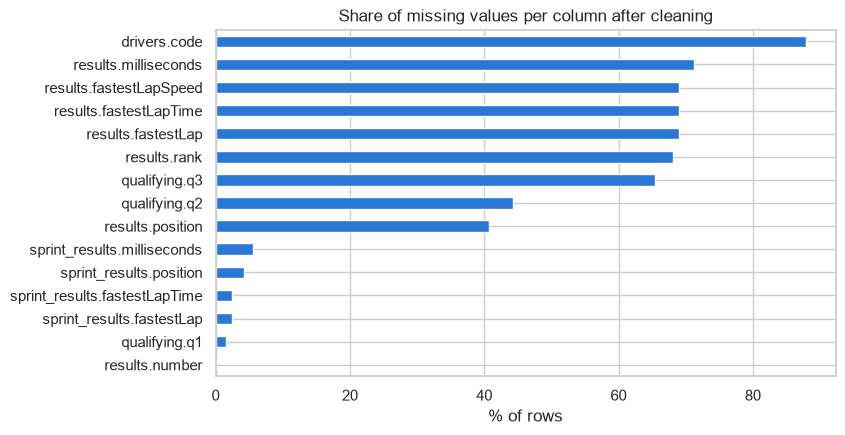

In [35]:
rows = []
for name in ["results", "qualifying", "sprint_results", "drivers"]:
    for col in clean[name].columns:
        share = clean[name][col].isna().mean() * 100
        if share > 0:
            rows.append({"column": f"{name}.{col}", "% missing": share})
missing_after = pd.DataFrame(rows).sort_values("% missing")

missing_after.plot.barh(x="column", y="% missing", figsize=(8, 4.5), legend=False)
plt.title("Share of missing values per column after cleaning")
plt.xlabel("% of rows")
plt.ylabel("")
plt.show()

Missing values are not all the same. Most of them are **missing by design**: the value cannot exist for that row.

| Column(s) | % missing | Why | Type |
|---|---|---|---|
| `qualifying.q3`, `qualifying.q2` | 65%, 44% | Drivers knocked out in Q1/Q2 never set a Q2/Q3 time; before 2006 qualifying had a single session | By design |
| `results.position` | 41% | The driver was not classified (retired, disqualified); `positionOrder`, our target, is never missing | By design |
| `results.milliseconds` | 71% | A total race time is only recorded for drivers who finished on the lead lap | By design |
| `results.fastestLap`, `fastestLapTime`, `fastestLapSpeed`, `rank` | 68–69% | Not recorded before the mid-2000s | Not recorded |
| `drivers.code` | 88% | Three-letter codes exist only for modern drivers | Not recorded |
| `qualifying.q1`, sprint columns | 1–6% | No time set / did not finish the sprint | Small gaps |

**Consequences for section 3:** the "by design" gaps carry information and should become flags (e.g. "reached Q3")
instead of being filled with an average. Most of the gappy columns (`position`, `milliseconds`, fastest lap) are
post-race information anyway, so they will never be features. The two columns we rely on most, `positionOrder` and
`grid`, have no missing values.

#### 1.5.3 Distributions we could not plot before cleaning

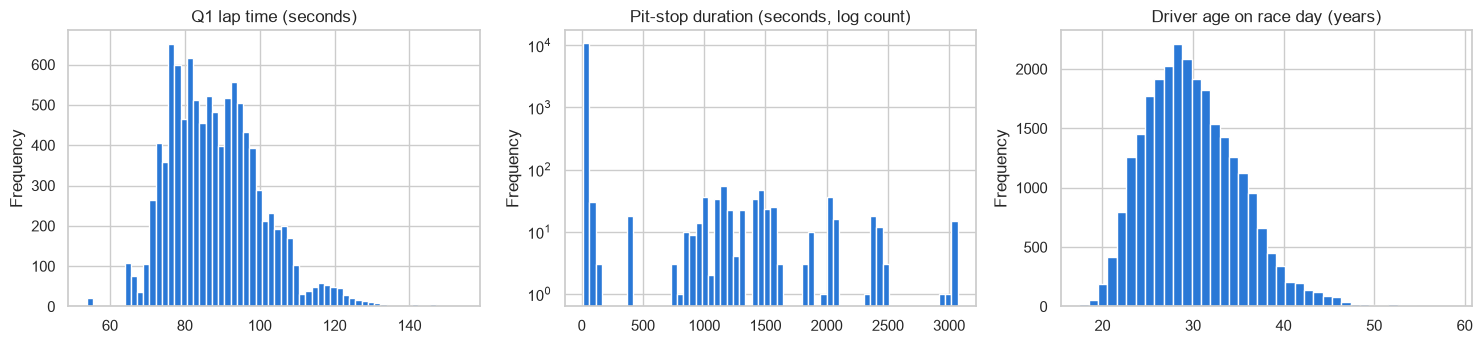

,count,mean,std,min,25%,50%,75%,max
Q1 time (s),10337.0,88.4,12.5,53.9,78.8,87.1,95.9,153.9
pit stop (s),11371.0,85.2,310.4,12.9,21.9,23.6,26.5,3069.0
driver age (years),26668.0,30.0,5.3,17.5,26.1,29.4,33.3,58.8


In [36]:
race_ages = (clean["results"]
             .merge(clean["races"][["raceId", "date"]], on="raceId")
             .merge(clean["drivers"][["driverId", "dob"]], on="driverId"))
driver_age = (race_ages["date"] - race_ages["dob"]).dt.days / 365.25

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
clean["qualifying"]["q1"].plot.hist(bins=60, ax=axes[0], title="Q1 lap time (seconds)")
clean["pit_stops"]["duration"].plot.hist(bins=60, ax=axes[1], logy=True,
                                         title="Pit-stop duration (seconds, log count)")
driver_age.plot.hist(bins=40, ax=axes[2], title="Driver age on race day (years)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Q1 time (s)": clean["qualifying"]["q1"].describe(),
    "pit stop (s)": clean["pit_stops"]["duration"].describe(),
    "driver age (years)": driver_age.describe(),
}).T.round(1)

- **Q1 lap time:** most values lie between about 54 and 150 seconds (median 87.1 s). The spread mainly comes
  from circuits of different lengths, so a raw lap time is not comparable across races. **Section 3 should use the
  gap to the fastest driver in the same session** instead.
  - This plot first revealed one impossible value: `16:42.640` (1,002.6 s) in the 1995 Japanese GP, where the
    fastest Q1 time was 1:38.0 and the median 1:41.5. It was a recording error and is now set to missing in
    **1.2.6**, so the distribution above is clean.
- **Pit-stop duration:** the median stop is 23.6 s, but there are clusters between about 400 and 3,069 s. These
  are red-flag interruptions (cars waiting in the pit lane), not real stops. Any pit-stop statistic must use the
  median or exclude these values.
- **Driver age on race day:** from 17.5 to 58.8 years (median 29.4). This plot was only possible after parsing
  `dob` and `date` as real dates, and the plausible range confirms the date parsing worked.

#### 1.5.4 Effect of cleaning on the target

,rows,podium rows,podium rate
before cleaning,26759,3397,12.69%
after cleaning,26668,3395,12.73%


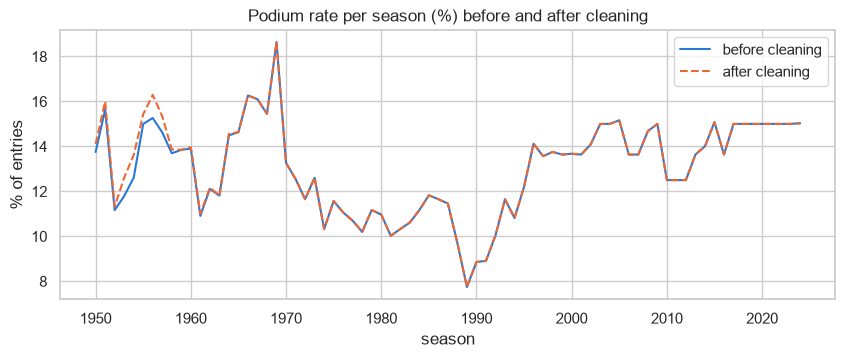

In [37]:
podium_before = raw["results"]["positionOrder"] <= 3
podium_after = clean["results"]["positionOrder"] <= 3
target_effect = pd.DataFrame({
    "rows": [len(raw["results"]), len(clean["results"])],
    "podium rows": [podium_before.sum(), podium_after.sum()],
    "podium rate": [f"{podium_before.mean():.2%}", f"{podium_after.mean():.2%}"],
}, index=["before cleaning", "after cleaning"])
display(target_effect)

year_of = clean["races"].set_index("raceId")["year"]
rate_before = podium_before.groupby(raw["results"]["raceId"].map(year_of)).mean() * 100
rate_after = podium_after.groupby(clean["results"]["raceId"].map(year_of)).mean() * 100
pd.DataFrame({"before cleaning": rate_before, "after cleaning": rate_after}).plot(
    figsize=(10, 3.5), style=["-", "--"])
plt.title("Podium rate per season (%) before and after cleaning")
plt.xlabel("season")
plt.ylabel("% of entries")
plt.show()

- The cleaning removed 91 rows and 2 podium rows. The 2 podium rows were the same drivers counted twice (shared
  drives), so **no driver's podium was lost**.
- The podium rate barely moves: **12.69% → 12.73%**.
- The per-season plot shows the two lines are identical from 1979 onward. The only differences are in the
  1950s, where the duplicated shared-drive rows were removed. **The cleaning did not distort the target** in the
  seasons we will model.

#### 1.5.5 Summary

| What cleaning did | Effect on the data | What it means next |
|---|---|---|
| Replaced 160,076 `\N` placeholders | Real missing values are now visible (e.g. 103,272 in `results`) | Most gaps are "by design" → flags in section 3, not averages |
| Retyped 18 columns (numbers, dates, seconds) | Times and dates can be plotted and computed | Q1 times differ by circuit → use the gap to pole |
| Dropped 20 unused columns | Smaller, clearer tables | — |
| One row per driver per race (−91 rows) | Grain fixed, no podium lost | `clean["results"]` is ready for the modelling table (3.2) |
| Fixed the Marussia team id in `qualifying` | Qualifying and race agree on the team | Team features use `results.constructorId` |

**Found during this EDA:** one impossible Q1 time (1995), which is now **fixed in 1.2.6** (set to missing), and
red-flag pit stops (400–3,069 s), which are real records and are kept. They are inside the modelling window
(pit-stop data starts in 2011), so if pit-stop times are ever used as a feature they must be summarised with the
median.

## 2. Data-Engineering Questions

### 2.1 Front-Row Starts to Podiums by Circuit: Qualifying vs. Grid and the 2014 Hybrid Era

### 2.2 Home-Country Podium Advantage Controlling for Starting Position

### 2.3 Constructor Mechanical-Retirement Rates: 2014–2021 vs. 2022–2024

## 3. Feature Selection & Engineering

### 3.1 Pre-Race Prediction Cutoff and Leakage Audit

### 3.2 Unique Driver-Race Modeling Table and Podium Target

### 3.3 Leakage-Safe Historical Form, Standings, Grid, and Qualifying Features

### 3.4 EDA Evidence and Feature-Selection Justification

### 3.5 Training, Validation, and Test Split

### 3.6 Preprocessing, Encoding, and Effects on Feature Distributions

## 4. Predictive Modeling Task

### 4.1 Baseline and Primary/Secondary Evaluation Metrics

### 4.2 Statistical Model 1

### 4.3 Statistical Model 2

### 4.4 Shallow Neural Network

### 4.5 Hyperparameter and Threshold Selection on Training/Validation Data

### 4.6 Model Comparison: Training, Validation, and Unseen Test Performance

### 4.7 Evaluation Plots and Model Limitations

## 5. Experiments

### 5.1 Feature-Group Ablation

### 5.2 Preprocessing-Order Experiment 1

### 5.3 Preprocessing-Order Experiment 2

### 5.4 Experiment Comparison and Interpretation

## 6. Model Explainability (XAI)

### 6.1 Global Permutation Importance

### 6.2 Global SHAP Explanations

### 6.3 Local Prediction Explanation: LIME and/or SHAP

### 6.4 Interpretation and Non-Causal Limitations

## 7. Inference Function

### 7.1 Inference Pipeline

### 7.2 Demonstration with a Complete Record

### 7.3 Demonstration with a Partially Missing Record